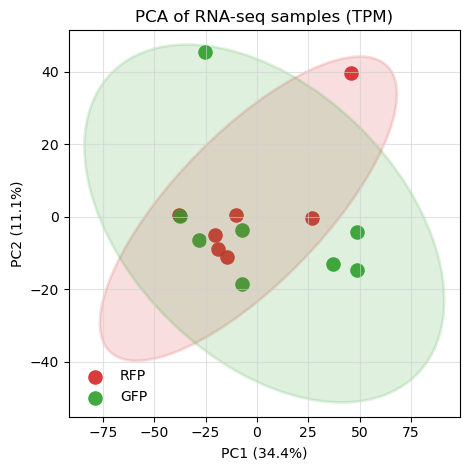

Saved: PCA_TPM_GFPpos_RFPneg.svg
group
GFP    8
RFP    7
Name: count, dtype: int64


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.patches import Ellipse

# ======================
# Input / Output
# ======================
TPM_PATH = "tpms.tsv"
OUT_SVG = "PCA_TPM_GFPpos_RFPneg.svg"

# ======================
# Plot settings
# ======================
# Colors: GFP+ in green, GFP- (= RFP) in red
COLOR_MAP = {
    "GFP": "#2CA02C",   # green
    "RFP": "#D62728",   # red
    "Other": "#B0B0B0"
}

DOT_SIZE = 110
ELLIPSE_ALPHA = 0.15
ELLIPSE_LW = 2.0

# PCA settings
TOP_VAR_GENES = 3000  # Top variable genes (recommended)
mpl.rcParams["svg.fonttype"] = "none"  # Keep text editable for Adobe Illustrator

# ======================
# Helper: infer group from sample name
# ======================
def infer_group(sample: str) -> str:
    # Definition: GFP- corresponds to RFP (red), GFP+ corresponds to GFP (green)
    if "GFP-" in sample:
        return "RFP"
    if "GFP+" in sample:
        return "GFP"
    return "Other"

# ======================
# Helper: confidence ellipse (95%)
# ======================
def add_confidence_ellipse(ax, x, y, color, alpha=0.15, lw=2.0):
    """
    Draw a 95% confidence ellipse assuming a 2D Gaussian distribution.
    Does not require sklearn. Recommended for n >= 3.
    """
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    if len(x) < 3:
        return  # Too few points for a stable estimate

    cov = np.cov(x, y)
    if not np.all(np.isfinite(cov)):
        return

    # Eigen decomposition
    vals, vecs = np.linalg.eigh(cov)
    order = vals.argsort()[::-1]
    vals, vecs = vals[order], vecs[:, order]

    # 95% confidence interval (chi-square, df=2) ≈ 5.991
    chi2_val = 5.991
    width, height = 2.0 * np.sqrt(vals * chi2_val)

    # Ellipse rotation angle
    angle = np.degrees(np.arctan2(vecs[1, 0], vecs[0, 0]))

    ell = Ellipse(
        (np.mean(x), np.mean(y)),
        width=width,
        height=height,
        angle=angle,
        facecolor=color,
        edgecolor=color,
        alpha=alpha,
        lw=lw
    )
    ax.add_patch(ell)

# ======================
# Load TPM data
# ======================
expr = pd.read_csv(TPM_PATH, sep="\t", index_col=0)

# log2(TPM + 1) transformation
expr_log = np.log2(expr + 1)

# Matrix orientation: samples x genes
X = expr_log.T
samples = X.index.to_list()

# ======================
# High-variance gene selection (recommended)
# ======================
var = X.var(axis=0)
top_genes = var.sort_values(ascending=False).head(TOP_VAR_GENES).index
X = X.loc[:, top_genes]

# ======================
# Standardization (gene-wise)
# ======================
Xv = X.values
Xv = (Xv - Xv.mean(axis=0)) / Xv.std(axis=0, ddof=1)

# ======================
# PCA via SVD
# ======================
U, S, Vt = np.linalg.svd(Xv, full_matrices=False)
PCs = U[:, :2] * S[:2]
var_explained = (S**2) / np.sum(S**2)

pc_df = pd.DataFrame(PCs, index=samples, columns=["PC1", "PC2"])
pc_df["group"] = [infer_group(s) for s in samples]

# ======================
# Plot
# ======================
fig, ax = plt.subplots(figsize=(4.8, 4.8))

# Scatter plot by group
for g in ["RFP", "GFP", "Other"]:
    sub = pc_df[pc_df["group"] == g]
    if sub.empty:
        continue
    ax.scatter(
        sub["PC1"], sub["PC2"],
        s=DOT_SIZE,
        color=COLOR_MAP[g],
        label=g,
        alpha=0.9,
        linewidths=0
    )

# Confidence ellipses (RFP and GFP only)
for g in ["RFP", "GFP"]:
    sub = pc_df[pc_df["group"] == g]
    if len(sub) >= 3:
        add_confidence_ellipse(
            ax,
            sub["PC1"].values,
            sub["PC2"].values,
            color=COLOR_MAP[g],
            alpha=ELLIPSE_ALPHA,
            lw=ELLIPSE_LW
        )

# Sample labels (optional; keep commented for final figure)
# for s in pc_df.index:
#     ax.text(pc_df.loc[s, "PC1"], pc_df.loc[s, "PC2"], s,
#             fontsize=8, ha="left", va="bottom")

ax.set_xlabel(f"PC1 ({var_explained[0]*100:.1f}%)")
ax.set_ylabel(f"PC2 ({var_explained[1]*100:.1f}%)")
ax.set_title("PCA of RNA-seq samples (TPM)")

# Grid (added for readability)
ax.grid(
    True,
    which="both",
    axis="both",
    color="#D0D0D0",
    linewidth=0.8,
    alpha=0.6,
    zorder=0
)

ax.legend(frameon=False)

fig.tight_layout()
fig.savefig(OUT_SVG)
plt.show()

print("Saved:", OUT_SVG)
print(pc_df["group"].value_counts())


In [8]:
!pip install adjustText

Significant UP genes: 1
Significant DOWN genes: 5
Labeled UP genes: 1
Labeled DOWN genes: 5
Significant UP genes: 1
Myogenic UP genes matched: 1


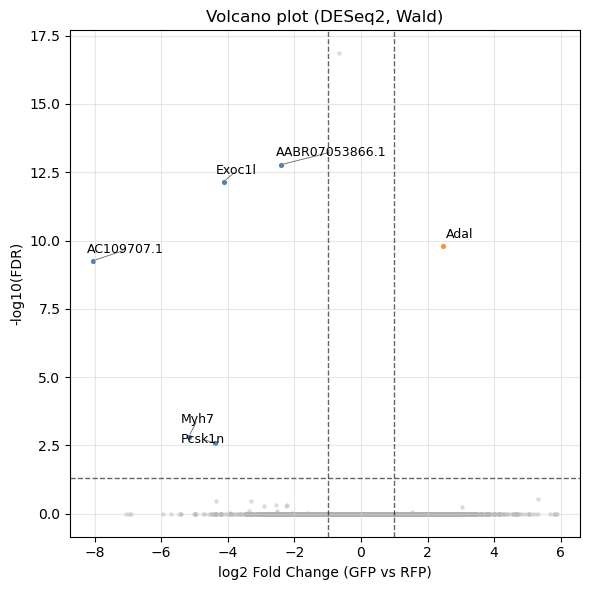

Saved: volcano_GFP_vs_RFP.svg
Labeled down genes: 5 (top 15)
Labeled up genes (myogenic only): 1 (top 20)


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from adjustText import adjust_text

# ======================
# Settings
# ======================
DE_PATH = "DE.tsv"
SVG_OUT = "volcano_GFP_vs_RFP.svg"

LOG2FC_CUTOFF = 1.0
FDR_CUTOFF = 0.05

LABEL_DOWN_TOP_N = 15
LABEL_UP_TOP_N   = 20  # If few myogenic candidates exist, this will effectively be smaller
LABEL_FONT_SIZE  = 9

POINT_SIZE_NS  = 10
POINT_SIZE_SIG = 14

COLOR_NS = "#B0B0B0"  # gray
COLOR_UP = "#F28E2B"  # orange
COLOR_DN = "#4E79A7"  # blue

MYOGENIC_GENES = {
    "Pax7","Myod1","Myog","Myf5","Myf6",
    "Des","Acta1","Tnnt1","Tnnt2","Tnnc1","Tnni1","Tnni2",
    "Myh1","Myh2","Myh3","Myh4","Myh6","Myh7","Myh8","Cdkn1a",
    "Myl1","Myl2","Myl3","Myl4",
    "Ckm","Tpm1","Tpm2","Tpm3","Mymk",
    "Neb","Ttn",
    "Cacna1s","Ryr1","Atp2a1","Atp2a2","Casq1","Casq2",
    "Dmd","Dysf","Dag1","Sgca","Sgcb","Sgcd","Sgsg",
    "Itga7","Vcam1",
    "Mef2c","Mef2d",

    # ---- myoblast fusion machinery ----
    "Myomaker","Tmem8c",
    "Myomixer","Myomerger","Minion"
}

# Keep text as text objects in SVG (for Adobe Illustrator)
mpl.rcParams["svg.fonttype"] = "none"

# ======================
# Load and preprocess
# ======================
df = pd.read_csv(DE_PATH, sep="\t").rename(columns={"Unnamed: 0": "Ensembl"})

# Check required columns
required_cols = ["Symbol", "log2FC", "padj"]
missing = [c for c in required_cols if c not in df.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}. Found: {df.columns.tolist()}")

df["Symbol"] = df["Symbol"].astype(str)
df["log2FC"] = pd.to_numeric(df["log2FC"], errors="coerce")
df["padj"]   = pd.to_numeric(df["padj"], errors="coerce")
df = df.dropna(subset=["log2FC", "padj"]).copy()

# -log10(FDR)
df["neglog10"] = -np.log10(df["padj"].clip(lower=1e-300))

# Significance masks
sig = (df["padj"] < FDR_CUTOFF) & (df["log2FC"].abs() >= LOG2FC_CUTOFF)
up  = sig & (df["log2FC"] > 0)
dn  = sig & (df["log2FC"] < 0)
ns  = ~sig

# ======================
# Select genes to label
# ======================
# Downregulated: label top N significant genes (smallest padj first)
label_down_df = (
    df.loc[dn]
      .sort_values(["padj", "log2FC"], ascending=[True, True])
      .drop_duplicates(subset=["Symbol"])
      .head(LABEL_DOWN_TOP_N)
)

# ======================
# Select genes to label
# ======================

# Downregulated: label top N significant genes
label_down_df = (
    df.loc[dn]
      .sort_values(["padj", "log2FC"], ascending=[True, True])
      .drop_duplicates(subset=["Symbol"])
      .head(LABEL_DOWN_TOP_N)
)

# Upregulated: label top N significant genes
label_up_df = (
    df.loc[up]
      .sort_values(["padj", "log2FC"], ascending=[True, False])
      .drop_duplicates(subset=["Symbol"])
      .head(LABEL_UP_TOP_N)
)

print("Significant UP genes:", int(up.sum()))
print("Significant DOWN genes:", int(dn.sum()))
print("Labeled UP genes:", len(label_up_df))
print("Labeled DOWN genes:", len(label_down_df))
# Report how many myogenic UP genes were actually matched
print("Significant UP genes:", int(up.sum()))
print("Myogenic UP genes matched:", len(label_up_df))

# ======================
# Plot
# ======================
fig, ax = plt.subplots(figsize=(6, 6))

ax.scatter(df.loc[ns, "log2FC"], df.loc[ns, "neglog10"],
           s=POINT_SIZE_NS, alpha=0.45, c=COLOR_NS, linewidths=0)

ax.scatter(df.loc[up, "log2FC"], df.loc[up, "neglog10"],
           s=POINT_SIZE_SIG, alpha=0.95, c=COLOR_UP, linewidths=0)

ax.scatter(df.loc[dn, "log2FC"], df.loc[dn, "neglog10"],
           s=POINT_SIZE_SIG, alpha=0.95, c=COLOR_DN, linewidths=0)

# Threshold lines
ax.axvline(LOG2FC_CUTOFF, linestyle="--", linewidth=1, color="black", alpha=0.6)
ax.axvline(-LOG2FC_CUTOFF, linestyle="--", linewidth=1, color="black", alpha=0.6)
ax.axhline(-np.log10(FDR_CUTOFF), linestyle="--", linewidth=1, color="black", alpha=0.6)

# ======================
# Labels + adjustText
# ======================
texts = []

for _, r in label_down_df.iterrows():
    texts.append(
        ax.text(r["log2FC"], r["neglog10"], str(r["Symbol"]),
                fontsize=LABEL_FONT_SIZE, ha="right", va="bottom")
    )

for _, r in label_up_df.iterrows():
    texts.append(
        ax.text(r["log2FC"], r["neglog10"], str(r["Symbol"]),
                fontsize=LABEL_FONT_SIZE, ha="left", va="bottom")
    )

adjust_text(
    texts,
    ax=ax,
    expand_text=(1.05, 1.15),
    expand_points=(1.05, 1.20),
    force_text=(0.2, 0.35),
    force_points=(0.2, 0.35),
    lim=500,
    arrowprops=dict(arrowstyle="-", color="black", lw=0.6, alpha=0.6)
)

ax.set_xlabel("log2 Fold Change (GFP vs RFP)")
ax.set_ylabel("-log10(FDR)")
ax.set_title("Volcano plot (DESeq2, Wald)")

ax.grid(True, color="#D0D0D0", linewidth=0.8, alpha=0.5)

fig.tight_layout()
fig.savefig(SVG_OUT, format="svg")
plt.show()

print("Saved:", SVG_OUT)
print(f"Labeled down genes: {len(label_down_df)} (top {LABEL_DOWN_TOP_N})")
print(f"Labeled up genes (myogenic only): {len(label_up_df)} (top {LABEL_UP_TOP_N})")


In [7]:
import pandas as pd
import urllib.parse
import urllib.request
from pathlib import Path

# ======================
# Settings
# ======================
TPM_PATH = "tpms.tsv"
OUT_PATH = "gene_annotation.tsv"

# ======================
# Read TPM Ensembl IDs
# ======================
tpm_path = Path(TPM_PATH)

if not tpm_path.exists():
    raise FileNotFoundError(f"{TPM_PATH} not found. Put tpms.tsv in the current working directory.")

tpm = pd.read_csv(tpm_path, sep="\t", index_col=0)

tpm_ids = (
    pd.Index(tpm.index.astype(str))
    .str.replace(r"\.\d+$", "", regex=True)  # remove Ensembl version suffix
    .unique()
)

print(f"TPM Ensembl IDs: {len(tpm_ids)}")
print(tpm_ids[:5])

# ======================
# Download rat annotation from Ensembl BioMart
# ======================
xml = """<?xml version="1.0" encoding="UTF-8"?>
<!DOCTYPE Query>
<Query virtualSchemaName="default" formatter="TSV" header="1" uniqueRows="1" count="" datasetConfigVersion="0.6">
  <Dataset name="rnorvegicus_gene_ensembl" interface="default">
    <Attribute name="ensembl_gene_id" />
    <Attribute name="external_gene_name" />
  </Dataset>
</Query>
"""

query = urllib.parse.quote(xml)
url = "https://www.ensembl.org/biomart/martservice?query=" + query

print("Downloading rat Ensembl annotation from BioMart...")

with urllib.request.urlopen(url, timeout=120) as response:
    raw = response.read().decode("utf-8")

# ======================
# Parse BioMart result
# ======================
from io import StringIO

anno = pd.read_csv(StringIO(raw), sep="\t")
anno.columns = [c.strip() for c in anno.columns]

print("BioMart columns:", anno.columns.tolist())
print(anno.head())

# Detect columns
ens_col_candidates = ["Gene stable ID", "Ensembl Gene ID", "ensembl_gene_id"]
sym_col_candidates = ["Gene name", "External gene name", "external_gene_name"]

ens_col = next((c for c in ens_col_candidates if c in anno.columns), None)
sym_col = next((c for c in sym_col_candidates if c in anno.columns), None)

if ens_col is None or sym_col is None:
    raise ValueError(f"Could not detect Ensembl/Symbol columns. Found columns: {anno.columns.tolist()}")

anno = anno[[ens_col, sym_col]].rename(columns={ens_col: "Ensembl", sym_col: "Symbol"})

anno["Ensembl"] = (
    anno["Ensembl"]
    .astype(str)
    .str.replace(r"\.\d+$", "", regex=True)
)

anno["Symbol"] = anno["Symbol"].astype(str)

# Remove empty or invalid symbols
anno = anno[
    anno["Symbol"].notna()
    & (anno["Symbol"] != "")
    & (anno["Symbol"] != "nan")
].copy()

# ======================
# Filter to TPM genes
# ======================
gene_annotation = anno[
    anno["Ensembl"].isin(tpm_ids)
].drop_duplicates()

# If duplicated Ensembl IDs occur, keep the first symbol
gene_annotation = gene_annotation.drop_duplicates(subset=["Ensembl"], keep="first")

# Save
gene_annotation.to_csv(OUT_PATH, sep="\t", index=False)

print(f"Saved: {OUT_PATH}")
print(f"Annotated TPM IDs: {gene_annotation.shape[0]} / {len(tpm_ids)}")
gene_annotation.head(20)

TPM Ensembl IDs: 23978
Index(['ENSRNOG00000025794', 'ENSRNOG00000066272', 'ENSRNOG00000066412',
       'ENSRNOG00000070001', 'ENSRNOG00000070779'],
      dtype='object')
BioMart columns: ['Gene stable ID', 'Gene name']
       Gene stable ID    Gene name
0  ENSRNOG00000031780  AY172581.13
1  ENSRNOG00000030478   AY172581.9
2  ENSRNOG00000029171   AY172581.3
3  ENSRNOG00000081248          NaN
4  ENSRNOG00000032112  AY172581.14
Saved: gene_annotation.tsv
Annotated TPM IDs: 19004 / 23978


,Ensembl,Symbol
5,ENSRNOG00000030644,Mt-nd1
9,ENSRNOG00000031033,Mt-nd2
15,ENSRNOG00000034234,Mt-co1
18,ENSRNOG00000030371,Mt-co2
20,ENSRNOG00000033299,Mt-atp8
21,ENSRNOG00000031979,Mt-atp6
22,ENSRNOG00000030700,Mt-co3
24,ENSRNOG00000033615,Mt-nd3
26,ENSRNOG00000031053,Mt-nd4l
27,ENSRNOG00000029707,Mt-nd4


Requested RHO genes: 93
Found RHO genes: 92
Missing RHO genes: 1
Missing genes: ['Rhoq']
Genes retained after TPM filter: 92


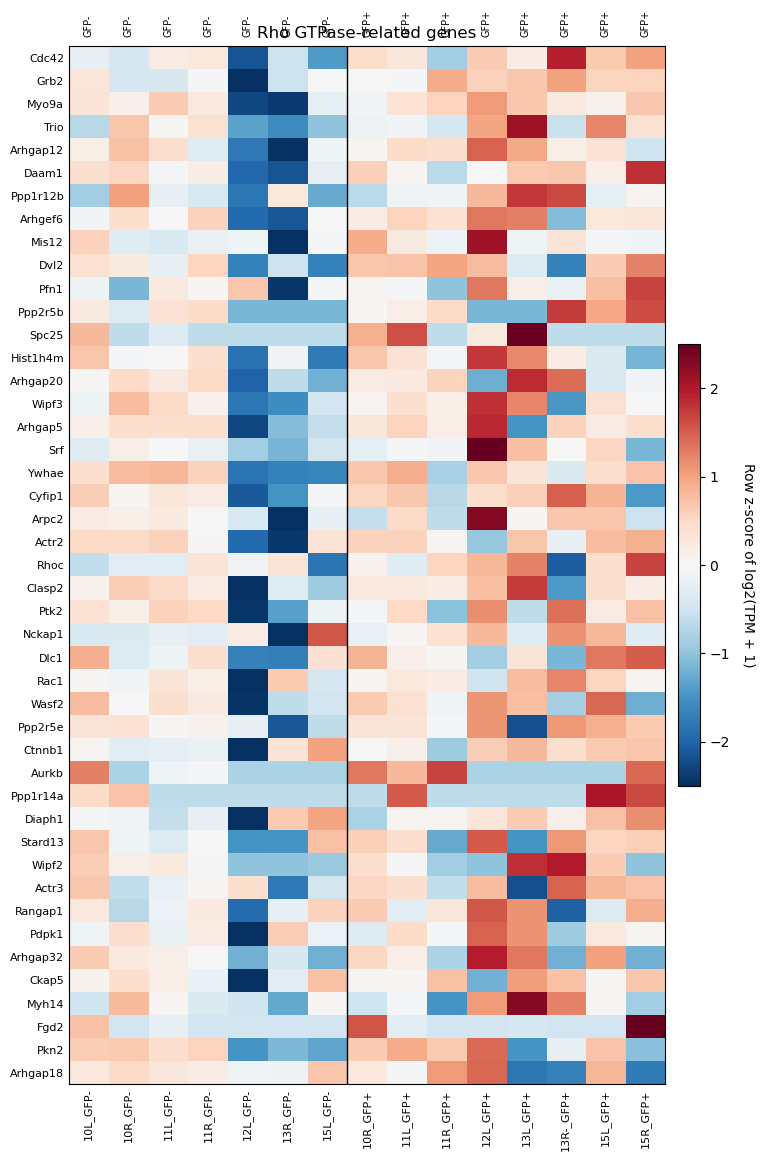

Saved: RHO_related_TPM_heatmap.svg


In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

# ======================
# Settings
# ======================
TPM_PATH = "tpms.tsv"
ANNOTATION_PATH = "gene_annotation.tsv"
SVG_OUT = "RHO_related_TPM_heatmap.svg"

MIN_MEAN_TPM = 0.5
MAX_GENES_TO_SHOW = 45

mpl.rcParams["svg.fonttype"] = "none"

RHO_GENES = [
    "Rac2", "Grb2", "Wipf2", "Arhgap5", "Hist1h4m", "Arhgap20", "Daam1",
    "Cdc42", "Arhgap12", "Ppp2r5b", "Rangap1", "Arhgef6", "Hist2h3c2",
    "Cyfip1", "Ppp2r5e", "Rhoq", "Birc5", "Myh14", "Mis12", "Fgd2",
    "Arhgap32", "Brk1", "Arhgap8", "Ppp1r12b", "Myo9a", "Spc25",
    "Ywhaq", "Actr3", "Ppp1r14a", "Stard13", "Dvl2", "Arhgap10",
    "Wasf2", "Pkn2", "Trio", "Srf", "Dlc1", "Arpc2", "Rhoc", "Ywhae",
    "Clasp2", "Pfn1", "Pdpk1", "Rac1", "Actr2", "Cenpm", "Arap1",
    "Zwint", "Nup85", "Incenp", "Nf2", "Mylk", "Ywhaz", "Aurkb",
    "Arhgef4", "Ywhah", "Ranbp2", "Xpo1", "Ar", "Arhgef5", "Ckap5",
    "Ctnnb1", "Arhgef7", "Vav2", "Kdm1a", "Nckap1", "Cyba", "Abi1",
    "Bub1", "Syde1", "Gna13", "Tagap", "Cenpt", "Scai", "Wipf3",
    "Arhgap18", "Dlg4", "Ptk2", "Ocrl", "Calm3", "Diaph1", "Clip1",
    "Nck1", "Ppp1cb", "Nudc", "Flna", "Arhgef2", "Arhgef18",
    "Arhgap28", "Abl1", "Srgap1", "Srgap3", "Ppp2r5a"
]

# ======================
# Load TPM
# ======================
tpm = pd.read_csv(TPM_PATH, sep="\t", index_col=0)
tpm.index = tpm.index.astype(str)

# Remove Ensembl version suffix
tpm["Ensembl_base"] = tpm.index.str.replace(r"\.\d+$", "", regex=True)

# ======================
# Load annotation
# ======================
anno = pd.read_csv(ANNOTATION_PATH, sep="\t")

if "Ensembl" not in anno.columns or "Symbol" not in anno.columns:
    raise ValueError("gene_annotation.tsv must contain columns: Ensembl and Symbol")

anno["Ensembl_base"] = anno["Ensembl"].astype(str).str.replace(r"\.\d+$", "", regex=True)
anno["Symbol"] = anno["Symbol"].astype(str)

# ======================
# Merge TPM with Symbol
# ======================
tpm_anno = tpm.merge(
    anno[["Ensembl_base", "Symbol"]].drop_duplicates(),
    on="Ensembl_base",
    how="left"
)

tpm_anno = tpm_anno.dropna(subset=["Symbol"]).copy()

sample_cols = [c for c in tpm_anno.columns if c not in ["Ensembl_base", "Symbol"]]

tpm_symbol = (
    tpm_anno
    .groupby("Symbol")[sample_cols]
    .mean()
)

# ======================
# Subset RHO genes
# ======================
available_genes = [g for g in RHO_GENES if g in tpm_symbol.index]
missing_genes = [g for g in RHO_GENES if g not in tpm_symbol.index]

print(f"Requested RHO genes: {len(RHO_GENES)}")
print(f"Found RHO genes: {len(available_genes)}")
print(f"Missing RHO genes: {len(missing_genes)}")
print("Missing genes:", missing_genes)

rho_tpm = tpm_symbol.loc[available_genes].copy()

# Filter low-expression genes
rho_tpm = rho_tpm.loc[rho_tpm.mean(axis=1) >= MIN_MEAN_TPM]

print(f"Genes retained after TPM filter: {rho_tpm.shape[0]}")

# ======================
# log2(TPM + 1), row z-score
# ======================
rho_log = np.log2(rho_tpm + 1)

rho_z = rho_log.sub(rho_log.mean(axis=1), axis=0)
rho_z = rho_z.div(rho_log.std(axis=1).replace(0, np.nan), axis=0)
rho_z = rho_z.fillna(0).clip(-2.5, 2.5)

# ======================
# Sort samples
# ======================
gfp_minus_samples = [c for c in rho_z.columns if "GFP-" in c]
gfp_plus_samples  = [c for c in rho_z.columns if "GFP+" in c]

sample_order = gfp_minus_samples + gfp_plus_samples
rho_z = rho_z[sample_order]

# ======================
# Sort genes by GFP+ - GFP-
# ======================
delta = rho_z[gfp_plus_samples].mean(axis=1) - rho_z[gfp_minus_samples].mean(axis=1)

if rho_z.shape[0] > MAX_GENES_TO_SHOW:
    top_genes = delta.abs().sort_values(ascending=False).head(MAX_GENES_TO_SHOW).index
    rho_z = rho_z.loc[top_genes]
    delta = delta.loc[top_genes]

rho_z = rho_z.loc[delta.sort_values(ascending=False).index]

# ======================
# Plot
# ======================
n_genes, n_samples = rho_z.shape

fig_width = max(6, 0.35 * n_samples + 2.5)
fig_height = max(6, 0.22 * n_genes + 1.8)

fig, ax = plt.subplots(figsize=(fig_width, fig_height))

im = ax.imshow(
    rho_z.values,
    aspect="auto",
    interpolation="nearest",
    vmin=-2.5,
    vmax=2.5,
    cmap="RdBu_r"
)

cbar = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02)
cbar.set_label("Row z-score of log2(TPM + 1)", rotation=270, labelpad=18)

ax.set_xticks(np.arange(n_samples))
ax.set_xticklabels(sample_order, rotation=90, fontsize=8)

ax.set_yticks(np.arange(n_genes))
ax.set_yticklabels(rho_z.index.tolist(), fontsize=8)

if len(gfp_minus_samples) > 0 and len(gfp_plus_samples) > 0:
    ax.axvline(len(gfp_minus_samples) - 0.5, color="black", linewidth=1)

for i, s in enumerate(sample_order):
    group = "GFP+" if "GFP+" in s else "GFP-"
    ax.text(i, -0.9, group, ha="center", va="bottom", fontsize=7, rotation=90)

ax.set_title("Rho GTPase-related genes", fontsize=12)
ax.tick_params(axis="both", length=0)

fig.tight_layout()
fig.savefig(SVG_OUT, format="svg", bbox_inches="tight")
plt.show()

print("Saved:", SVG_OUT)

Requested RHO genes: 93
Found RHO genes: 92
Missing RHO genes: 1
Missing genes: ['Rhoq']
Genes retained after TPM filter: 92


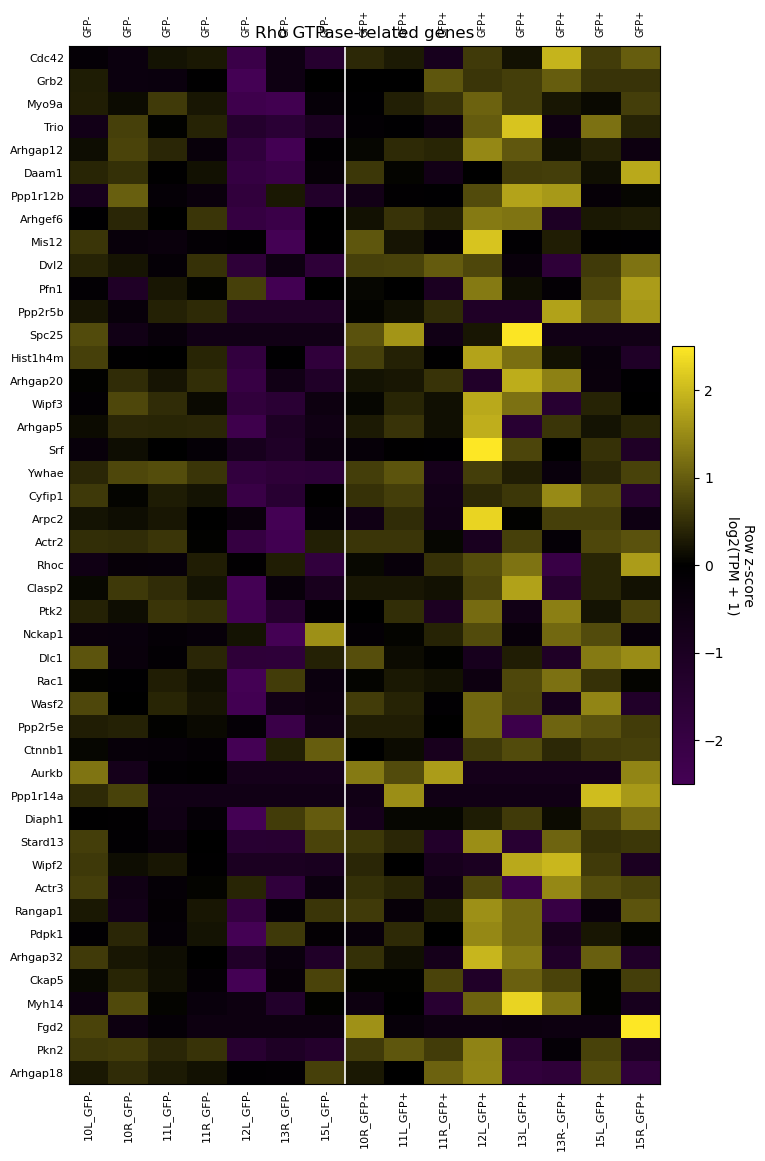

Saved: RHO_related_TPM_heatmap.svg


In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap

# ======================
# Settings
# ======================
TPM_PATH = "tpms.tsv"
ANNOTATION_PATH = "gene_annotation.tsv"
SVG_OUT = "RHO_related_TPM_heatmap.svg"

MIN_MEAN_TPM = 0.5
MAX_GENES_TO_SHOW = 45

# Keep text editable in Illustrator
mpl.rcParams["svg.fonttype"] = "none"

# ======================
# Custom colormap
# Low = deep purple, Center = black, High = yellow
# ======================
purple_black_yellow = LinearSegmentedColormap.from_list(
    "purple_black_yellow",
    [
        "#440154",  # low: deep purple
        "#000000",  # center: black
        "#FDE725"   # high: yellow
    ],
    N=256
)

# ======================
# RHO-related genes
# ======================
RHO_GENES = [
    "Rac2", "Grb2", "Wipf2", "Arhgap5", "Hist1h4m", "Arhgap20", "Daam1",
    "Cdc42", "Arhgap12", "Ppp2r5b", "Rangap1", "Arhgef6", "Hist2h3c2",
    "Cyfip1", "Ppp2r5e", "Rhoq", "Birc5", "Myh14", "Mis12", "Fgd2",
    "Arhgap32", "Brk1", "Arhgap8", "Ppp1r12b", "Myo9a", "Spc25",
    "Ywhaq", "Actr3", "Ppp1r14a", "Stard13", "Dvl2", "Arhgap10",
    "Wasf2", "Pkn2", "Trio", "Srf", "Dlc1", "Arpc2", "Rhoc", "Ywhae",
    "Clasp2", "Pfn1", "Pdpk1", "Rac1", "Actr2", "Cenpm", "Arap1",
    "Zwint", "Nup85", "Incenp", "Nf2", "Mylk", "Ywhaz", "Aurkb",
    "Arhgef4", "Ywhah", "Ranbp2", "Xpo1", "Ar", "Arhgef5", "Ckap5",
    "Ctnnb1", "Arhgef7", "Vav2", "Kdm1a", "Nckap1", "Cyba", "Abi1",
    "Bub1", "Syde1", "Gna13", "Tagap", "Cenpt", "Scai", "Wipf3",
    "Arhgap18", "Dlg4", "Ptk2", "Ocrl", "Calm3", "Diaph1", "Clip1",
    "Nck1", "Ppp1cb", "Nudc", "Flna", "Arhgef2", "Arhgef18",
    "Arhgap28", "Abl1", "Srgap1", "Srgap3", "Ppp2r5a"
]

# ======================
# Load TPM
# ======================
tpm = pd.read_csv(TPM_PATH, sep="\t", index_col=0)
tpm.index = tpm.index.astype(str)

# Remove Ensembl version suffix
tpm["Ensembl_base"] = tpm.index.str.replace(r"\.\d+$", "", regex=True)

# ======================
# Load annotation
# ======================
anno = pd.read_csv(ANNOTATION_PATH, sep="\t")

if "Ensembl" not in anno.columns or "Symbol" not in anno.columns:
    raise ValueError("gene_annotation.tsv must contain columns: Ensembl and Symbol")

anno["Ensembl_base"] = (
    anno["Ensembl"]
    .astype(str)
    .str.replace(r"\.\d+$", "", regex=True)
)

anno["Symbol"] = anno["Symbol"].astype(str)

# ======================
# Merge TPM with Symbol
# ======================
tpm_anno = tpm.merge(
    anno[["Ensembl_base", "Symbol"]].drop_duplicates(),
    on="Ensembl_base",
    how="left"
)

tpm_anno = tpm_anno.dropna(subset=["Symbol"]).copy()

sample_cols = [
    c for c in tpm_anno.columns
    if c not in ["Ensembl_base", "Symbol"]
]

# If multiple Ensembl IDs map to the same Symbol, average TPMs
tpm_symbol = (
    tpm_anno
    .groupby("Symbol")[sample_cols]
    .mean()
)

# ======================
# Subset RHO genes
# ======================
available_genes = [g for g in RHO_GENES if g in tpm_symbol.index]
missing_genes = [g for g in RHO_GENES if g not in tpm_symbol.index]

print(f"Requested RHO genes: {len(RHO_GENES)}")
print(f"Found RHO genes: {len(available_genes)}")
print(f"Missing RHO genes: {len(missing_genes)}")
print("Missing genes:", missing_genes)

rho_tpm = tpm_symbol.loc[available_genes].copy()

# Filter low-expression genes
rho_tpm = rho_tpm.loc[rho_tpm.mean(axis=1) >= MIN_MEAN_TPM]

print(f"Genes retained after TPM filter: {rho_tpm.shape[0]}")

# ======================
# log2(TPM + 1), row z-score
# ======================
rho_log = np.log2(rho_tpm + 1)

rho_z = rho_log.sub(rho_log.mean(axis=1), axis=0)
rho_z = rho_z.div(rho_log.std(axis=1).replace(0, np.nan), axis=0)

rho_z = rho_z.fillna(0)
rho_z = rho_z.clip(-2.5, 2.5)

# ======================
# Sort samples
# ======================
# Assumes sample names contain "GFP-" or "GFP+"
gfp_minus_samples = [c for c in rho_z.columns if "GFP-" in c]
gfp_plus_samples  = [c for c in rho_z.columns if "GFP+" in c]

if len(gfp_minus_samples) == 0 or len(gfp_plus_samples) == 0:
    print("Warning: Could not detect GFP- or GFP+ samples from column names.")
    print("Current sample columns:")
    print(rho_z.columns.tolist())

sample_order = gfp_minus_samples + gfp_plus_samples
rho_z = rho_z[sample_order]

# ======================
# Sort genes by GFP+ - GFP-
# ======================
delta = (
    rho_z[gfp_plus_samples].mean(axis=1)
    - rho_z[gfp_minus_samples].mean(axis=1)
)

# Select top genes by absolute group difference if too many
if rho_z.shape[0] > MAX_GENES_TO_SHOW:
    top_genes = (
        delta.abs()
        .sort_values(ascending=False)
        .head(MAX_GENES_TO_SHOW)
        .index
    )
    rho_z = rho_z.loc[top_genes]
    delta = delta.loc[top_genes]

# Order genes: higher in GFP+ at top
rho_z = rho_z.loc[delta.sort_values(ascending=False).index]

# ======================
# Plot heatmap
# ======================
n_genes, n_samples = rho_z.shape

fig_width = max(6, 0.35 * n_samples + 2.5)
fig_height = max(6, 0.22 * n_genes + 1.8)

fig, ax = plt.subplots(figsize=(fig_width, fig_height))

im = ax.imshow(
    rho_z.values,
    aspect="auto",
    interpolation="nearest",
    vmin=-2.5,
    vmax=2.5,
    cmap=purple_black_yellow
)

# Colorbar
cbar = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02)
cbar.set_label(
    "Row z-score\nlog2(TPM + 1)",
    rotation=270,
    labelpad=22
)

# X axis
ax.set_xticks(np.arange(n_samples))
ax.set_xticklabels(sample_order, rotation=90, fontsize=8)

# Y axis
ax.set_yticks(np.arange(n_genes))
ax.set_yticklabels(rho_z.index.tolist(), fontsize=8)

# Boundary between GFP- and GFP+
if len(gfp_minus_samples) > 0 and len(gfp_plus_samples) > 0:
    ax.axvline(
        len(gfp_minus_samples) - 0.5,
        color="white",
        linewidth=1.2
    )

# Group labels above heatmap
for i, s in enumerate(sample_order):
    group = "GFP+" if "GFP+" in s else "GFP-"
    ax.text(
        i,
        -0.9,
        group,
        ha="center",
        va="bottom",
        fontsize=7,
        rotation=90,
        color="black"
    )

ax.set_title("Rho GTPase-related genes", fontsize=12)
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis="both", length=0)

fig.tight_layout()
fig.savefig(SVG_OUT, format="svg", bbox_inches="tight")
plt.show()

print("Saved:", SVG_OUT)

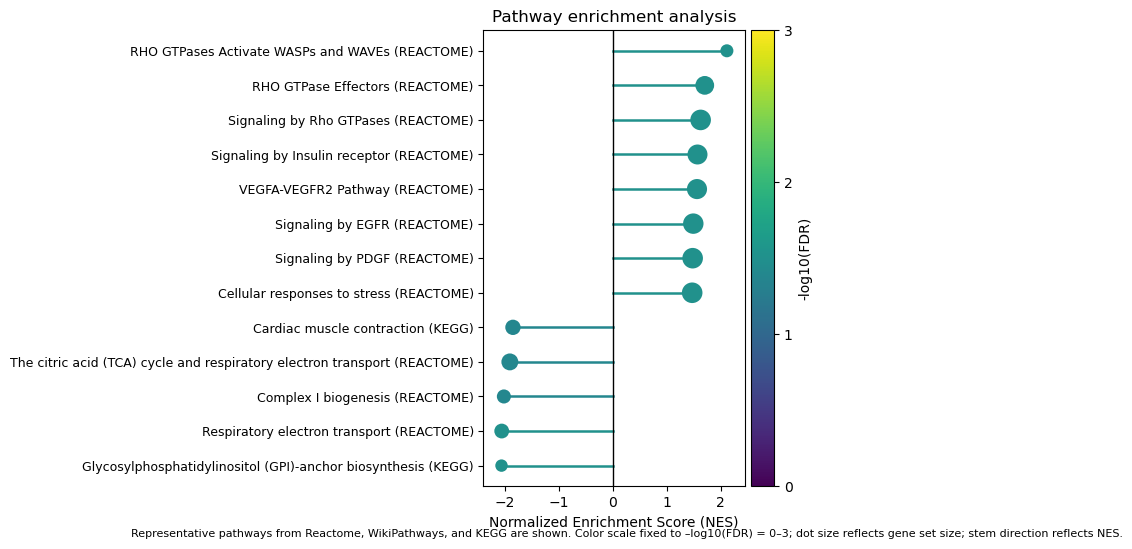

Saved: gsea_pathway_lollipop.svg
Rows plotted: 13
Up pathways: 8
Down pathways: 5
Size column used: size
Colorbar range: (0.0, 3.0)
    Database                                            Pathway       NES  \
0       KEGG  Glycosylphosphatidylinositol (GPI)-anchor bios... -2.060760   
1   REACTOME                     Respiratory electron transport -2.056676   
2   REACTOME                               Complex I biogenesis -2.016533   
3   REACTOME  The citric acid (TCA) cycle and respiratory el... -1.906042   
4       KEGG                         Cardiac muscle contraction -1.848662   
5   REACTOME                       Cellular responses to stress  1.473152   
6   REACTOME                                  Signaling by PDGF  1.482122   
7   REACTOME                                  Signaling by EGFR  1.493976   
8   REACTOME                               VEGFA-VEGFR2 Pathway  1.562507   
9   REACTOME                      Signaling by Insulin receptor  1.571897   
10  REACTOME         

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

# ======================
# Final lollipop plot
# ======================
IN_PATH = "GSEA_PathResults.tsv"
SVG_OUT = "gsea_pathway_lollipop.svg"

TOP_N_DOWN = 12
TOP_N_UP   = 8

STEM_LW = 1.8
MIN_S = 80
MAX_S = 220

CMAP = "viridis"

# ---- Colorbar range ----
CBAR_VMIN = 0.0
CBAR_VMAX = 3.0

# Keep text as text objects in SVG for Adobe Illustrator
mpl.rcParams["svg.fonttype"] = "none"

# ======================
# Load data
# ======================
df = pd.read_csv(IN_PATH, sep="\t")
df = df.drop(columns=["Unnamed: 0"], errors="ignore")

# ======================
# Optional: keep only databases used in the manuscript figure
# ======================
DATABASES_TO_KEEP = ["REACTOME", "WIKIPATHWAYS", "KEGG"]

if "Database" in df.columns:
    df = df[df["Database"].isin(DATABASES_TO_KEEP)].copy()
else:
    df["Database"] = "NA"

# Convert relevant columns to numeric
for c in ["NES", "padj", "p-value", "size", "numGenes"]:
    if c in df.columns:
        df[c] = pd.to_numeric(df[c], errors="coerce")

# Remove rows with missing NES or adjusted p-values
df = df.dropna(subset=["NES", "padj"]).copy()

# ======================
# Optional: exclude noisy / irrelevant terms from main figure
# ======================
EXCLUDE_PATTERNS = [
    "MicroRNAs in cancer",
    "GPI-anchor biosynthesis",
    "Nectin",
    "Necl",
    "Fc epsilon receptor",
]

for pat in EXCLUDE_PATTERNS:
    df = df[~df["Pathway"].str.contains(pat, case=False, na=False)].copy()

# ======================
# Collapse duplicated pathway names
# Keep entry with the largest absolute NES
# ======================
df = (
    df.sort_values("NES", key=lambda x: x.abs(), ascending=False)
      .drop_duplicates(subset=["Pathway"])
)

# ======================
# Select top enriched pathways
# ======================
down = df[df["NES"] < 0].sort_values("padj").head(TOP_N_DOWN)
up   = df[df["NES"] > 0].sort_values("padj").head(TOP_N_UP)

plot_df = pd.concat([down, up], axis=0).copy()

plot_df["neglog10FDR"] = -np.log10(plot_df["padj"].clip(lower=1e-300))

# Display label: add database name in parentheses
plot_df["Pathway_label"] = plot_df["Pathway"] + " (" + plot_df["Database"].astype(str) + ")"

# Sort by NES so negative pathways are lower/upper depending on y-axis order
plot_df = plot_df.sort_values("NES").reset_index(drop=True)

# ======================
# Dot size = gene set size
# ======================
size_col = "size"

if size_col not in plot_df.columns or plot_df[size_col].isna().all():
    if "numGenes" in plot_df.columns and not plot_df["numGenes"].isna().all():
        size_col = "numGenes"
    else:
        size_col = None

if size_col is None:
    size_scaled = np.full(len(plot_df), (MIN_S + MAX_S) / 2.0)
else:
    raw = pd.to_numeric(plot_df[size_col], errors="coerce").fillna(0).to_numpy()
    s0 = np.sqrt(raw)
    den = float(np.nanmax(s0) - np.nanmin(s0))

    if den < 1e-12:
        size_scaled = np.full_like(s0, (MIN_S + MAX_S) / 2.0)
    else:
        t = (s0 - float(np.nanmin(s0))) / den
        size_scaled = MIN_S + (MAX_S - MIN_S) * t

# ======================
# Color mapping = -log10(FDR)
# ======================
cvals = plot_df["neglog10FDR"].to_numpy(dtype=float)

norm = Normalize(vmin=CBAR_VMIN, vmax=CBAR_VMAX, clip=True)
cmap = plt.get_cmap(CMAP)
rgba = cmap(norm(cvals))

# ======================
# Plot
# ======================
fig, ax = plt.subplots(figsize=(7.5, 0.45 * len(plot_df)))

y = np.arange(len(plot_df))

# Stem lines
for i, r in enumerate(plot_df.itertuples()):
    ax.plot(
        [0, r.NES],
        [i, i],
        color=rgba[i],
        linewidth=STEM_LW,
        alpha=1.0,
        zorder=1
    )

# Dots
ax.scatter(
    plot_df["NES"],
    y,
    s=size_scaled,
    c=rgba,
    linewidths=0,
    zorder=3
)

# Central vertical line
ax.axvline(0, color="black", linewidth=1)

# Axis labels
ax.set_yticks(y)
ax.set_yticklabels(plot_df["Pathway_label"], fontsize=9)

ax.set_xlabel("Normalized Enrichment Score (NES)")
ax.set_title("Pathway enrichment analysis")

# Add horizontal padding
xmin, xmax = float(plot_df["NES"].min()), float(plot_df["NES"].max())
xrange = max(1e-9, xmax - xmin)
pad = max(0.25, 0.08 * xrange)
ax.set_xlim(xmin - pad, xmax + pad)

# Colorbar
sm = ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

cbar = fig.colorbar(sm, ax=ax, pad=0.02)
cbar.set_label("-log10(FDR)")
cbar.set_ticks([0, 1, 2, 3])

# Annotation at the bottom
fig.text(
    0.01,
    0.01,
    "Representative pathways from Reactome, WikiPathways, and KEGG are shown. "
    "Color scale fixed to –log10(FDR) = 0–3; dot size reflects gene set size; stem direction reflects NES.",
    ha="left",
    va="bottom",
    fontsize=8
)

# Increase left margin to prevent clipping of pathway names
fig.subplots_adjust(left=0.48, bottom=0.10)

# Save figure
fig.savefig(SVG_OUT, format="svg", bbox_inches="tight")
plt.show()

print("Saved:", SVG_OUT)
print("Rows plotted:", len(plot_df))
print("Up pathways:", int((plot_df["NES"] > 0).sum()))
print("Down pathways:", int((plot_df["NES"] < 0).sum()))
print("Size column used:", size_col)
print("Colorbar range:", (CBAR_VMIN, CBAR_VMAX))
print(plot_df[["Database", "Pathway", "NES", "padj"]])

Selected pathways requested: 12
Selected pathways found: 11
Missing selected pathways: ['TCA cycle and respiratory electron transport']


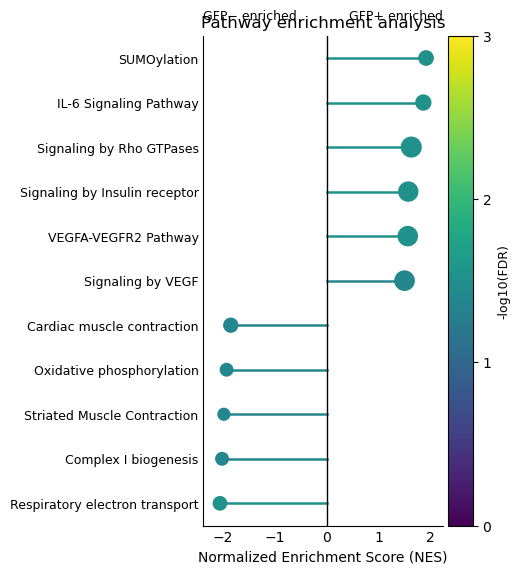

Saved: selected_gsea_lollipop.svg
Rows plotted: 11
GFP+ enriched pathways: 6
GFP− enriched pathways: 5
Size column used: size
Colorbar range: (0.0, 3.0)
                           Pathway       NES      padj
0   Respiratory electron transport -2.056676  0.031453
1             Complex I biogenesis -2.016533  0.040642
2      Striated Muscle Contraction -1.981471  0.042161
3        Oxidative phosphorylation -1.929462  0.042161
4       Cardiac muscle contraction -1.848662  0.042161
5                Signaling by VEGF  1.500409  0.040642
6             VEGFA-VEGFR2 Pathway  1.562507  0.031453
7    Signaling by Insulin receptor  1.571897  0.031453
8         Signaling by Rho GTPases  1.629961  0.031453
9           IL-6 Signaling Pathway  1.862711  0.031453
10                     SUMOylation  1.914558  0.031453


In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

# ======================
# Settings
# ======================
IN_PATH = "GSEA_PathResults.tsv"
SVG_OUT = "selected_gsea_lollipop.svg"

STEM_LW = 1.8
MIN_S = 90
MAX_S = 230

CMAP = "viridis"

# Colorbar range
CBAR_VMIN = 0.0
CBAR_VMAX = 3.0

# Keep text as text objects in SVG for Adobe Illustrator
mpl.rcParams["svg.fonttype"] = "none"

# ======================
# Pathways to show
# ======================
GFP_PLUS_PATHWAYS = [
    "Signaling by Rho GTPases",
    "SUMOylation",
    "IL-6 Signaling Pathway",
    "Signaling by Insulin receptor",
    "VEGFA-VEGFR2 Pathway",
    "Signaling by VEGF",
]

GFP_MINUS_PATHWAYS = [
    "Respiratory electron transport",
    "TCA cycle and respiratory electron transport",
    "Complex I biogenesis",
    "Oxidative phosphorylation",
    "Striated Muscle Contraction",
    "Cardiac muscle contraction",
]

SELECTED_PATHWAYS = GFP_MINUS_PATHWAYS + GFP_PLUS_PATHWAYS

# ======================
# Load data
# ======================
df = pd.read_csv(IN_PATH, sep="\t")
df = df.drop(columns=["Unnamed: 0"], errors="ignore")

# Check required columns
required_cols = ["Pathway", "NES", "padj"]
missing = [c for c in required_cols if c not in df.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}. Found columns: {df.columns.tolist()}")

# Convert relevant columns to numeric
for c in ["NES", "padj", "p-value", "size", "numGenes"]:
    if c in df.columns:
        df[c] = pd.to_numeric(df[c], errors="coerce")

df = df.dropna(subset=["Pathway", "NES", "padj"]).copy()

# ======================
# Select specified pathways
# ======================
plot_df = df[df["Pathway"].isin(SELECTED_PATHWAYS)].copy()

# If duplicated pathway names exist across databases, keep entry with largest |NES|
plot_df = (
    plot_df
    .sort_values("NES", key=lambda x: x.abs(), ascending=False)
    .drop_duplicates(subset=["Pathway"], keep="first")
)

# Check missing selected pathways
found_pathways = set(plot_df["Pathway"])
missing_pathways = [p for p in SELECTED_PATHWAYS if p not in found_pathways]

print("Selected pathways requested:", len(SELECTED_PATHWAYS))
print("Selected pathways found:", plot_df.shape[0])
print("Missing selected pathways:", missing_pathways)

# Keep the intended order:
# negative NES pathways first, then positive NES pathways,
# but sorted by NES so the plot naturally separates negative and positive.
plot_df["Pathway"] = pd.Categorical(
    plot_df["Pathway"],
    categories=SELECTED_PATHWAYS,
    ordered=True
)

plot_df["neglog10FDR"] = -np.log10(plot_df["padj"].clip(lower=1e-300))

# Sort by NES: negative at bottom/top depending y-axis; consistent lollipop layout
plot_df = plot_df.sort_values("NES").reset_index(drop=True)

# ======================
# Dot size = gene set size
# ======================
size_col = "size"

if size_col not in plot_df.columns or plot_df[size_col].isna().all():
    if "numGenes" in plot_df.columns and not plot_df["numGenes"].isna().all():
        size_col = "numGenes"
    else:
        size_col = None

if size_col is None:
    size_scaled = np.full(len(plot_df), (MIN_S + MAX_S) / 2.0)
else:
    raw = pd.to_numeric(plot_df[size_col], errors="coerce").fillna(0).to_numpy()
    s0 = np.sqrt(raw)

    den = float(np.nanmax(s0) - np.nanmin(s0))

    if den < 1e-12:
        size_scaled = np.full_like(s0, (MIN_S + MAX_S) / 2.0)
    else:
        t = (s0 - float(np.nanmin(s0))) / den
        size_scaled = MIN_S + (MAX_S - MIN_S) * t

# ======================
# Color mapping = -log10(FDR)
# ======================
cvals = plot_df["neglog10FDR"].to_numpy(dtype=float)

norm = Normalize(vmin=CBAR_VMIN, vmax=CBAR_VMAX, clip=True)
cmap = plt.get_cmap(CMAP)
rgba = cmap(norm(cvals))

# ======================
# Plot
# ======================
fig, ax = plt.subplots(figsize=(7.2, 0.48 * len(plot_df) + 1.0))

y = np.arange(len(plot_df))

# Stem lines
for i, r in enumerate(plot_df.itertuples()):
    ax.plot(
        [0, r.NES],
        [i, i],
        color=rgba[i],
        linewidth=STEM_LW,
        alpha=1.0,
        zorder=1
    )

# Dots
ax.scatter(
    plot_df["NES"],
    y,
    s=size_scaled,
    c=rgba,
    linewidths=0,
    zorder=3
)

# Central vertical line
ax.axvline(0, color="black", linewidth=1)

# Axis labels
ax.set_yticks(y)
ax.set_yticklabels(plot_df["Pathway"].astype(str), fontsize=9)

ax.set_xlabel("Normalized Enrichment Score (NES)", fontsize=10)
ax.set_title("Pathway enrichment analysis", fontsize=12)

# Add horizontal padding to prevent dot clipping
xmin = float(plot_df["NES"].min())
xmax = float(plot_df["NES"].max())
xrange = max(1e-9, xmax - xmin)
pad = max(0.25, 0.08 * xrange)
ax.set_xlim(xmin - pad, xmax + pad)

# Optional: label sides
ax.text(
    xmin - pad,
    len(plot_df) - 0.2,
    "GFP− enriched",
    ha="left",
    va="bottom",
    fontsize=9
)

ax.text(
    xmax + pad,
    len(plot_df) - 0.2,
    "GFP+ enriched",
    ha="right",
    va="bottom",
    fontsize=9
)

# Colorbar
sm = ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

cbar = fig.colorbar(sm, ax=ax, pad=0.02)
cbar.set_label("-log10(FDR)", fontsize=9)
cbar.set_ticks([0, 1, 2, 3])

# Clean aesthetics
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(axis="both", length=0)

# Increase left margin to prevent clipping of pathway names
fig.subplots_adjust(left=0.48, right=0.88, bottom=0.12, top=0.90)

# Save figure
fig.savefig(SVG_OUT, format="svg", bbox_inches="tight")
plt.show()

print("Saved:", SVG_OUT)
print("Rows plotted:", len(plot_df))
print("GFP+ enriched pathways:", int((plot_df["NES"] > 0).sum()))
print("GFP− enriched pathways:", int((plot_df["NES"] < 0).sum()))
print("Size column used:", size_col)
print("Colorbar range:", (CBAR_VMIN, CBAR_VMAX))
print(plot_df[["Pathway", "NES", "padj"]])

Selected pathways requested: 16
Selected pathways found: 13
Missing selected pathways: ['TCA cycle and respiratory electron transport', 'Muscle contraction', 'Pyruvate metabolism and TCA cycle']


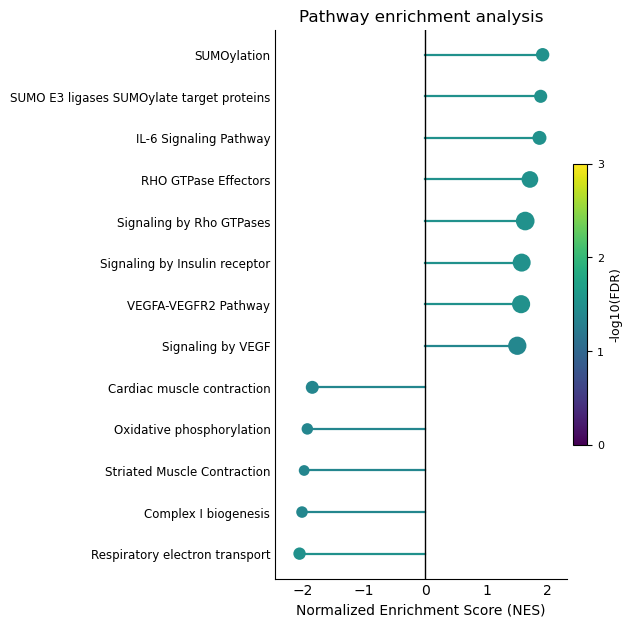

Saved: selected_gsea_lollipop.svg
Rows plotted: 13
GFP+ enriched pathways: 8
GFP− enriched pathways: 5
Size column used: size
Colorbar range: (0.0, 3.0)
                                      Pathway       NES      padj
0              Respiratory electron transport -2.056676  0.031453
1                        Complex I biogenesis -2.016533  0.040642
2                 Striated Muscle Contraction -1.981471  0.042161
3                   Oxidative phosphorylation -1.929462  0.042161
4                  Cardiac muscle contraction -1.848662  0.042161
5                           Signaling by VEGF  1.500409  0.040642
6                        VEGFA-VEGFR2 Pathway  1.562507  0.031453
7               Signaling by Insulin receptor  1.571897  0.031453
8                    Signaling by Rho GTPases  1.629961  0.031453
9                        RHO GTPase Effectors  1.706649  0.031453
10                     IL-6 Signaling Pathway  1.862711  0.031453
11  SUMO E3 ligases SUMOylate target proteins  1.882392

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

# ======================
# Settings
# ======================
IN_PATH = "GSEA_PathResults.tsv"
SVG_OUT = "selected_gsea_lollipop.svg"

STEM_LW = 1.6
MIN_S = 60
MAX_S = 180

CMAP = "viridis"

CBAR_VMIN = 0.0
CBAR_VMAX = 3.0

mpl.rcParams["svg.fonttype"] = "none"

# ======================
# Pathways to show
# ======================
GFP_PLUS_PATHWAYS = [
    "Signaling by Rho GTPases",
    "RHO GTPase Effectors",
    "SUMOylation",
    "SUMO E3 ligases SUMOylate target proteins",
    "IL-6 Signaling Pathway",
    "Signaling by Insulin receptor",
    "VEGFA-VEGFR2 Pathway",
    "Signaling by VEGF",
]

GFP_MINUS_PATHWAYS = [
    "Respiratory electron transport",
    "TCA cycle and respiratory electron transport",
    "Complex I biogenesis",
    "Oxidative phosphorylation",
    "Striated Muscle Contraction",
    "Cardiac muscle contraction",
    "Muscle contraction",
    "Pyruvate metabolism and TCA cycle",
]

SELECTED_PATHWAYS = GFP_MINUS_PATHWAYS + GFP_PLUS_PATHWAYS

# ======================
# Load data
# ======================
df = pd.read_csv(IN_PATH, sep="\t")
df = df.drop(columns=["Unnamed: 0"], errors="ignore")

required_cols = ["Pathway", "NES", "padj"]
missing = [c for c in required_cols if c not in df.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}. Found columns: {df.columns.tolist()}")

for c in ["NES", "padj", "p-value", "size", "numGenes"]:
    if c in df.columns:
        df[c] = pd.to_numeric(df[c], errors="coerce")

df = df.dropna(subset=["Pathway", "NES", "padj"]).copy()

# ======================
# Select specified pathways
# ======================
plot_df = df[df["Pathway"].isin(SELECTED_PATHWAYS)].copy()

# If duplicated pathway names exist across databases, keep the entry with largest |NES|
plot_df = (
    plot_df
    .sort_values("NES", key=lambda x: x.abs(), ascending=False)
    .drop_duplicates(subset=["Pathway"], keep="first")
)

found_pathways = set(plot_df["Pathway"])
missing_pathways = [p for p in SELECTED_PATHWAYS if p not in found_pathways]

print("Selected pathways requested:", len(SELECTED_PATHWAYS))
print("Selected pathways found:", plot_df.shape[0])
print("Missing selected pathways:", missing_pathways)

plot_df["neglog10FDR"] = -np.log10(plot_df["padj"].clip(lower=1e-300))

# Sort by NES
plot_df = plot_df.sort_values("NES").reset_index(drop=True)

# ======================
# Dot size = gene set size
# ======================
size_col = "size"

if size_col not in plot_df.columns or plot_df[size_col].isna().all():
    if "numGenes" in plot_df.columns and not plot_df["numGenes"].isna().all():
        size_col = "numGenes"
    else:
        size_col = None

if size_col is None:
    size_scaled = np.full(len(plot_df), (MIN_S + MAX_S) / 2.0)
else:
    raw = pd.to_numeric(plot_df[size_col], errors="coerce").fillna(0).to_numpy()
    s0 = np.sqrt(raw)
    den = float(np.nanmax(s0) - np.nanmin(s0))

    if den < 1e-12:
        size_scaled = np.full_like(s0, (MIN_S + MAX_S) / 2.0)
    else:
        t = (s0 - float(np.nanmin(s0))) / den
        size_scaled = MIN_S + (MAX_S - MIN_S) * t

# ======================
# Color mapping = -log10(FDR)
# ======================
cvals = plot_df["neglog10FDR"].to_numpy(dtype=float)

norm = Normalize(vmin=CBAR_VMIN, vmax=CBAR_VMAX, clip=True)
cmap = plt.get_cmap(CMAP)
rgba = cmap(norm(cvals))

# ======================
# Plot
# ======================
fig, ax = plt.subplots(figsize=(7.8, 0.42 * len(plot_df) + 1.4))

y = np.arange(len(plot_df))

# Stem lines
for i, r in enumerate(plot_df.itertuples()):
    ax.plot(
        [0, r.NES],
        [i, i],
        color=rgba[i],
        linewidth=STEM_LW,
        alpha=1.0,
        zorder=1
    )

# Dots
ax.scatter(
    plot_df["NES"],
    y,
    s=size_scaled,
    c=rgba,
    linewidths=0,
    zorder=3
)

# Central vertical line
ax.axvline(0, color="black", linewidth=1)

# Axis labels
ax.set_yticks(y)
ax.set_yticklabels(plot_df["Pathway"].astype(str), fontsize=8.5)

ax.set_xlabel("Normalized Enrichment Score (NES)", fontsize=10)
ax.set_title("Pathway enrichment analysis", fontsize=12)

# Add horizontal padding
xmin = float(plot_df["NES"].min())
xmax = float(plot_df["NES"].max())
xrange = max(1e-9, xmax - xmin)
pad = max(0.35, 0.10 * xrange)
ax.set_xlim(xmin - pad, xmax + pad)

# Colorbar
sm = ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

cbar = fig.colorbar(sm, ax=ax, pad=0.02, fraction=0.045)
cbar.set_label("-log10(FDR)", fontsize=9)
cbar.set_ticks([0, 1, 2, 3])
cbar.ax.tick_params(labelsize=8)

# Clean aesthetics
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(axis="both", length=0)

# Margins
fig.subplots_adjust(left=0.48, right=0.88, bottom=0.12, top=0.92)

# Save figure
fig.savefig(SVG_OUT, format="svg", bbox_inches="tight")
plt.show()

print("Saved:", SVG_OUT)
print("Rows plotted:", len(plot_df))
print("GFP+ enriched pathways:", int((plot_df["NES"] > 0).sum()))
print("GFP− enriched pathways:", int((plot_df["NES"] < 0).sum()))
print("Size column used:", size_col)
print("Colorbar range:", (CBAR_VMIN, CBAR_VMAX))
print(plot_df[["Pathway", "NES", "padj"]])